# EDA Analysis 
## Roles to explore 


In [6]:
#EDA ANALYSIS 
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x:ast.literal_eval(x) if pd.notna(x) else x)


## Filter for India Data Analyst

In [3]:
df_DA_IN = df[(df['job_country'] == 'India') & (df['job_title_short'] == 'Data Analyst')]

df_DA_IN['job_location'].value_counts().head(10)

job_location
India                             2056
Hyderabad, Telangana, India       1289
Anywhere                          1052
Bengaluru, Karnataka, India        355
Maharashtra, India                 203
Mumbai, Maharashtra, India         133
Pune, Maharashtra, India           119
Gurugram, Haryana, India           108
Chennai, Tamil Nadu, India         106
Secunderabad, Telangana, India      84
Name: count, dtype: int64

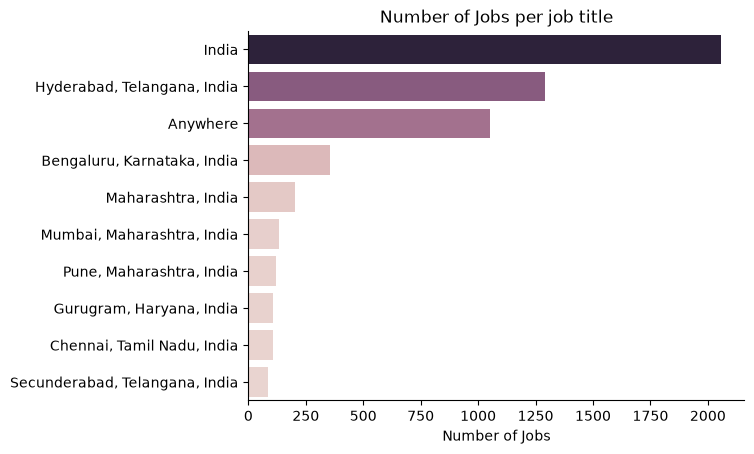

In [10]:
df_plot = df_DA_IN['job_location'].value_counts().head(10).to_frame()

sns.barplot(data=df_plot,x='count',y='job_location',hue='count',legend=False)
sns.despine() #remove border around graph

plt.title('Number of Jobs per job title')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()


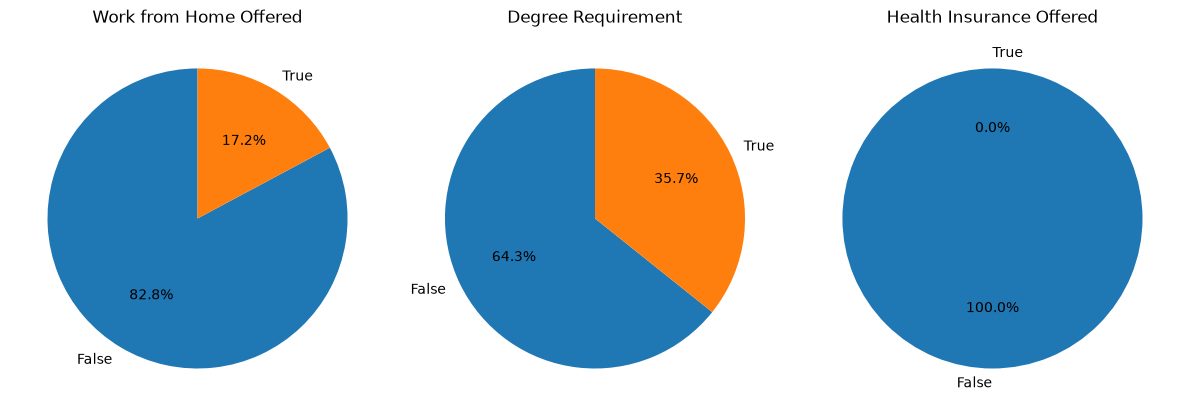

In [21]:

# Pie Charts to denote Work from Home, Degree Requirement, and Health Insurance

dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health Insurance Offered'
}

fig, ax = plt.subplots(1, 3)
fig.set_size_inches(12, 5)

for i, (column, title) in enumerate(dict_column.items()):
    counts = df_DA_IN[column].value_counts().reindex([False, True], fill_value=0)

    ax[i].pie(
        counts,
        labels=['False', 'True'],
        autopct='%1.1f%%',
        startangle=90
    )

    ax[i].set_title(title)

plt.tight_layout()
plt.show()


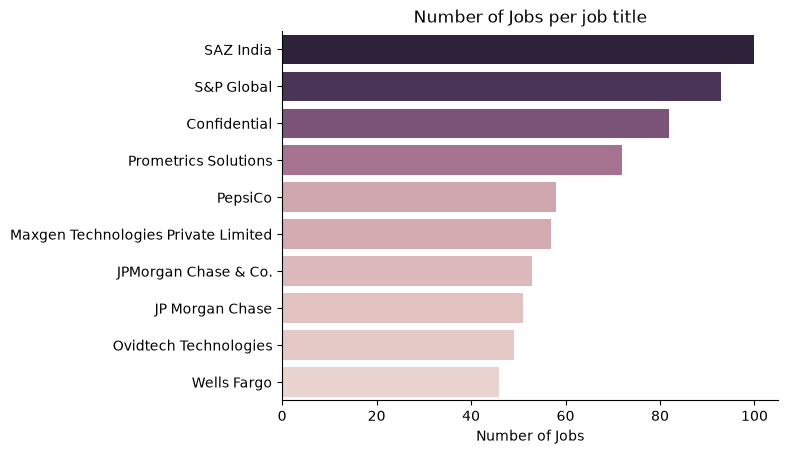

In [22]:
df_plot = df_DA_IN['company_name'].value_counts().head(10).to_frame()

sns.barplot(data=df_plot,x='count',y='company_name',hue='count',legend=False)
sns.despine() #remove border around graph

plt.title('Number of Jobs per job title')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()
